# 05 · CatBoost Research
Does changing E3's estimator to CatBoost improve weighted markout prediction or the economic filtering Score?

E9 uses the exact saved E3 sample and 81-feature schema, with identical targets, weights and purges.
It adds no feature search, early stopping or February fitting. Read frozen tables under `catboost/v1/`.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'pyproject.toml').exists())
sys.path.insert(0, str(ROOT/'src'))
sys.path.insert(0, str(ROOT))
from research_paths import artifact_dir
import research_report as report
report.style()
def show(fig, name):
    path=ROOT/'artifacts/figures'/name
    fig.savefig(path, dpi=150)
    display(Image(filename=str(path)))
    plt.close(fig)

## Fixed estimator and provenance
Three CatBoostRegressor models predict 30/120/300-second markouts.
Training uses weighted RMSE (equivalently the same squared-error optimum) on grouped markout means.
Full-trade MSE is reconstructed with within-group residuals, so a training RMSE is not the official evaluation MSE.

In [2]:
spec=json.loads((artifact_dir('catboost')/'v1/experiment_specification.json').read_text())
from maker_hybrid.features import feature_columns
assert spec['features']==feature_columns('E3')
assert not spec['validation_labels_used_for_fit'] and not spec['hyperparameter_search']
display(pd.Series(spec['parameters'],name='fixed value').to_frame())
print('Feature count:',len(spec['features']))
print('Frozen training-sample SHA-256:',spec['training_sample_sha256'])

,fixed value
loss_function,RMSE
iterations,32
depth,4
learning_rate,0.050000
l2_leaf_reg,3.000000
random_seed,20261017
thread_count,4
task_type,CPU
boosting_type,Plain
grow_policy,SymmetricTree


Feature count: 81
Frozen training-sample SHA-256: 6c290a578542803f1fe533ecfd84a85e118b36213891db790a2433221d4fa309


## Maker Score and regression error
The main comparison matches $250m/day total across BTC and ETH on February, using each model's fixed rank scores.
February matching uses scores and weights, not markout labels, but is still a retrospective turnover calibration.
January-threshold transfer is examined separately in notebook 06.

,model,tau,score,pnl_all,pnl_kept,pnl_filtered,kept_turnover_per_day
247,E3,30,5.148496,-0.046409,5.102086,-0.094224,"250,000,082.296406"
255,E3,120,6.735727,-0.032564,6.703163,-0.095121,"250,000,505.058242"
263,E3,300,5.531530,0.024532,5.556062,-0.026842,"250,000,074.445579"
787,E9,30,4.691114,-0.046409,4.644704,-0.089977,"250,000,640.852053"
795,E9,120,10.377586,-0.032564,10.345022,-0.128944,"250,000,001.786071"
803,E9,300,-0.096945,0.024532,-0.072413,0.025433,"250,000,149.531035"


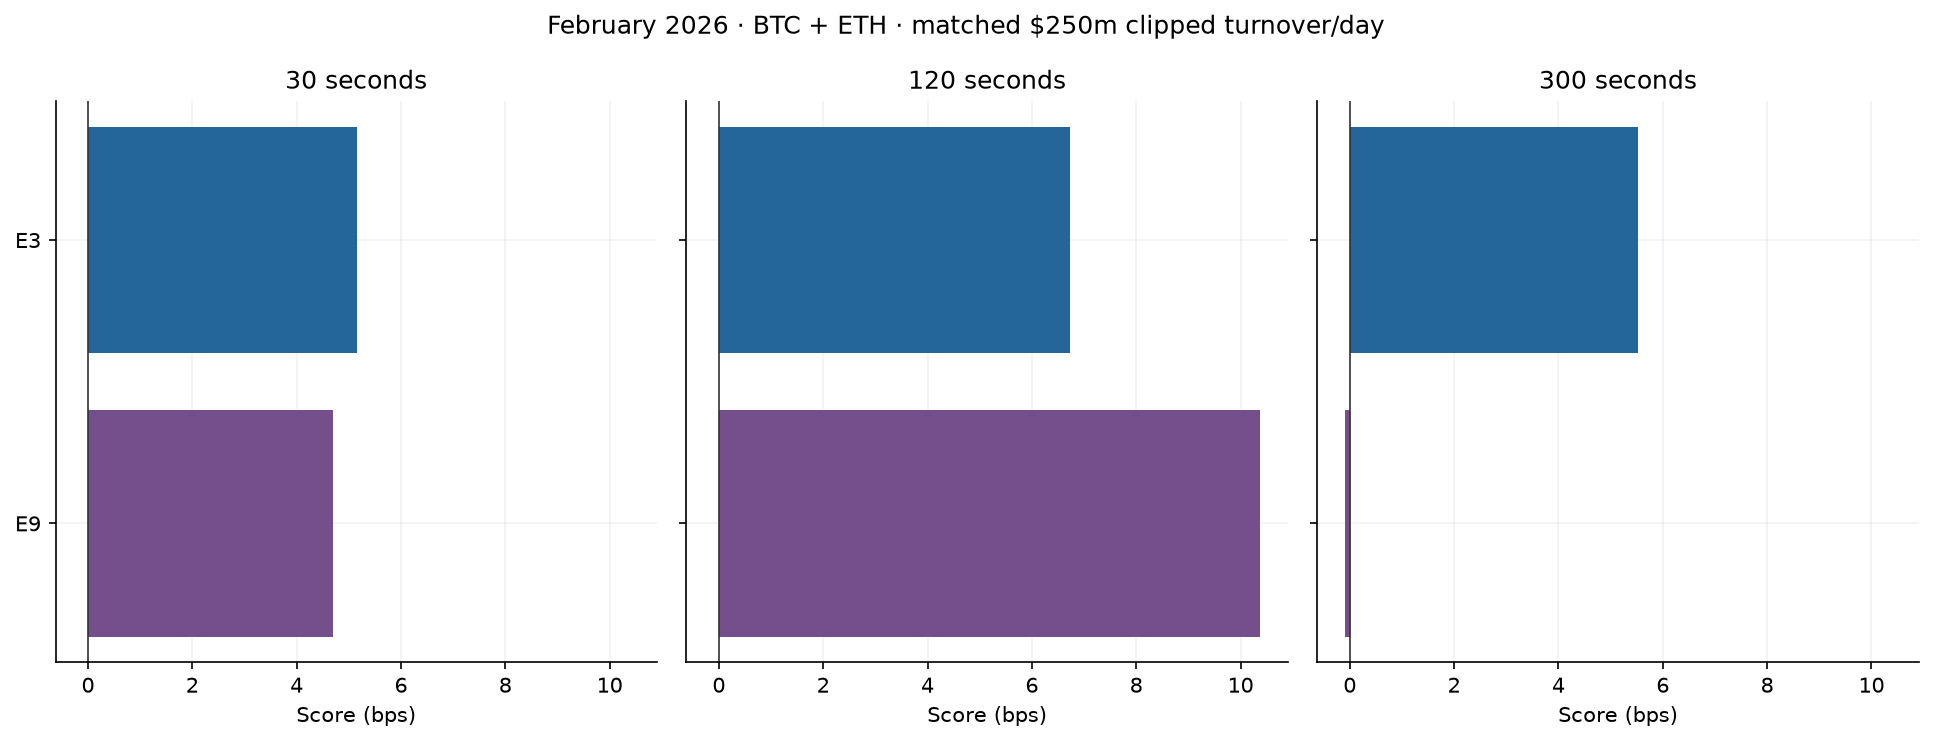

In [3]:
display(report.primary(['E3','E9'])[['model','tau','score','pnl_all','pnl_kept','pnl_filtered','kept_turnover_per_day']])
show(report.score_figure(['E3','E9']),'catboost_scores.png')

,period,model,symbol,tau,weighted_trade_mse_bps2
22,validation,E9,combined,30,269.176298
23,validation,E3,combined,30,269.054356
28,validation,E9,combined,120,734.133387
29,validation,E3,combined,120,737.599802
34,validation,E9,combined,300,"1,550.627586"
35,validation,E3,combined,300,"1,550.603199"


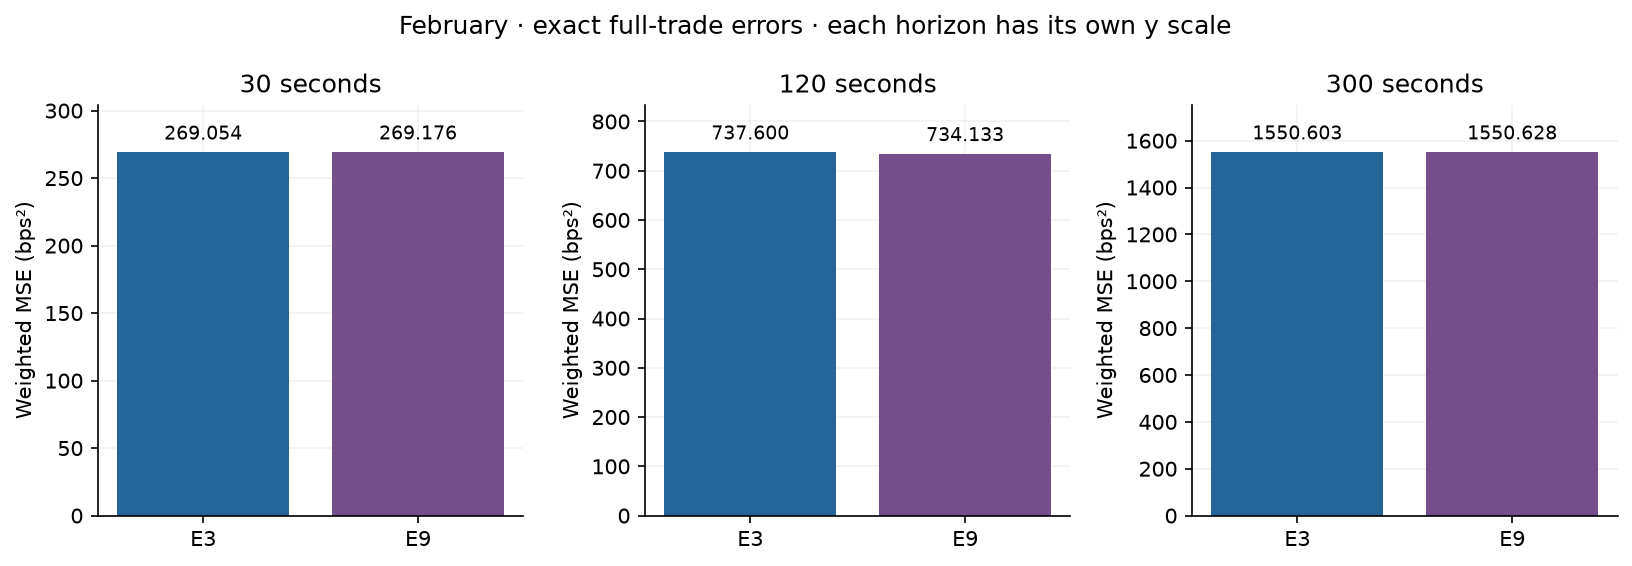

In [4]:
mse=report.table('catboost','v1/regression_error_diagnostics.csv').query("period=='validation' and symbol=='combined'")
display(mse)
show(report.mse_figure(),'regression_mse.png')

E9 Score is 4.691114 / 10.377586 / −0.096945 bps versus E3's 5.148496 / 6.735727 / 5.531530.
Its better 120-second point Score does not establish a general estimator improvement.
A low global weighted MSE need not produce a strong Score in the small retained tail.

## Paired statistical comparison
The primary family contains E9−E3 at three horizons, combined $250m/day.
The table includes 1-day and 5-day paired resampling; the chart uses the 5-day sensitivity with Bonferroni coverage.

,tau,delta_score,ci_low,ci_high,confidence_level,finite_bootstrap_fraction
31,30,-0.457382,-6.709376,3.591752,0.983333,1.000000
39,120,3.641859,-0.275751,10.389352,0.983333,1.000000
47,300,-5.628475,-18.420533,3.604793,0.983333,1.000000


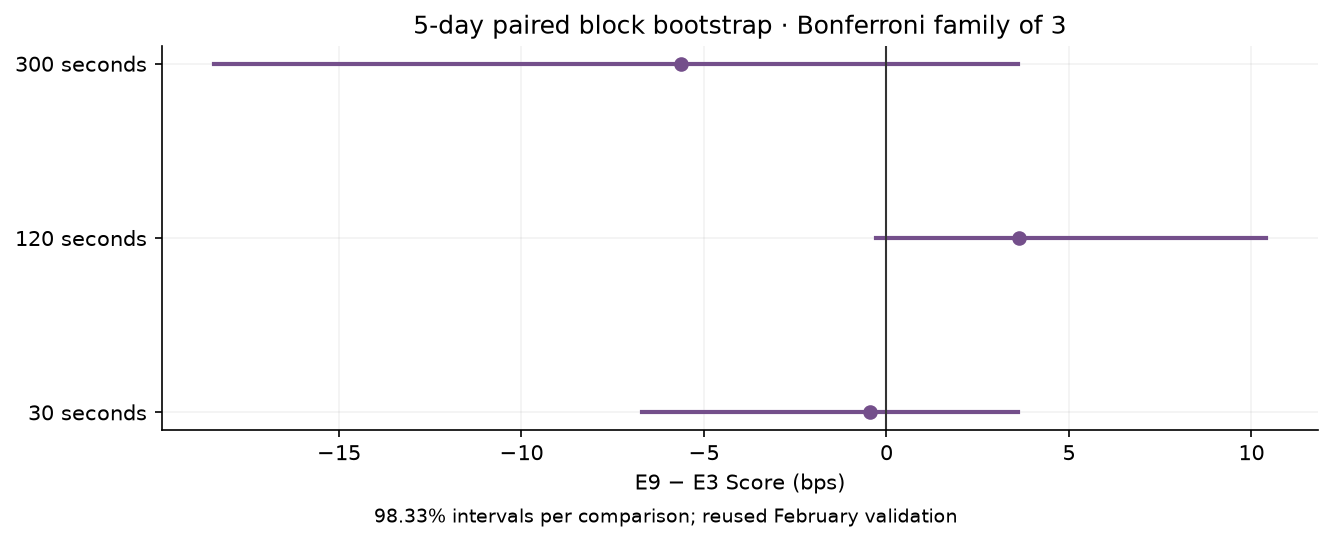

In [5]:
paired=report.table('catboost','v1/paired_e9_e3.csv').query('primary_family_bonferroni and block_days==5')
display(paired[['tau','delta_score','ci_low','ci_high','confidence_level','finite_bootstrap_fraction']])
assert ((paired.ci_low<=0)&(paired.ci_high>=0)).all()
show(report.paired_figure(),'catboost_paired_intervals.png')

All adjusted paired intervals include zero. Bootstrap uncertainty does not correct for repeated strategy selection
on February. This is descriptive evidence from a reused validation month.

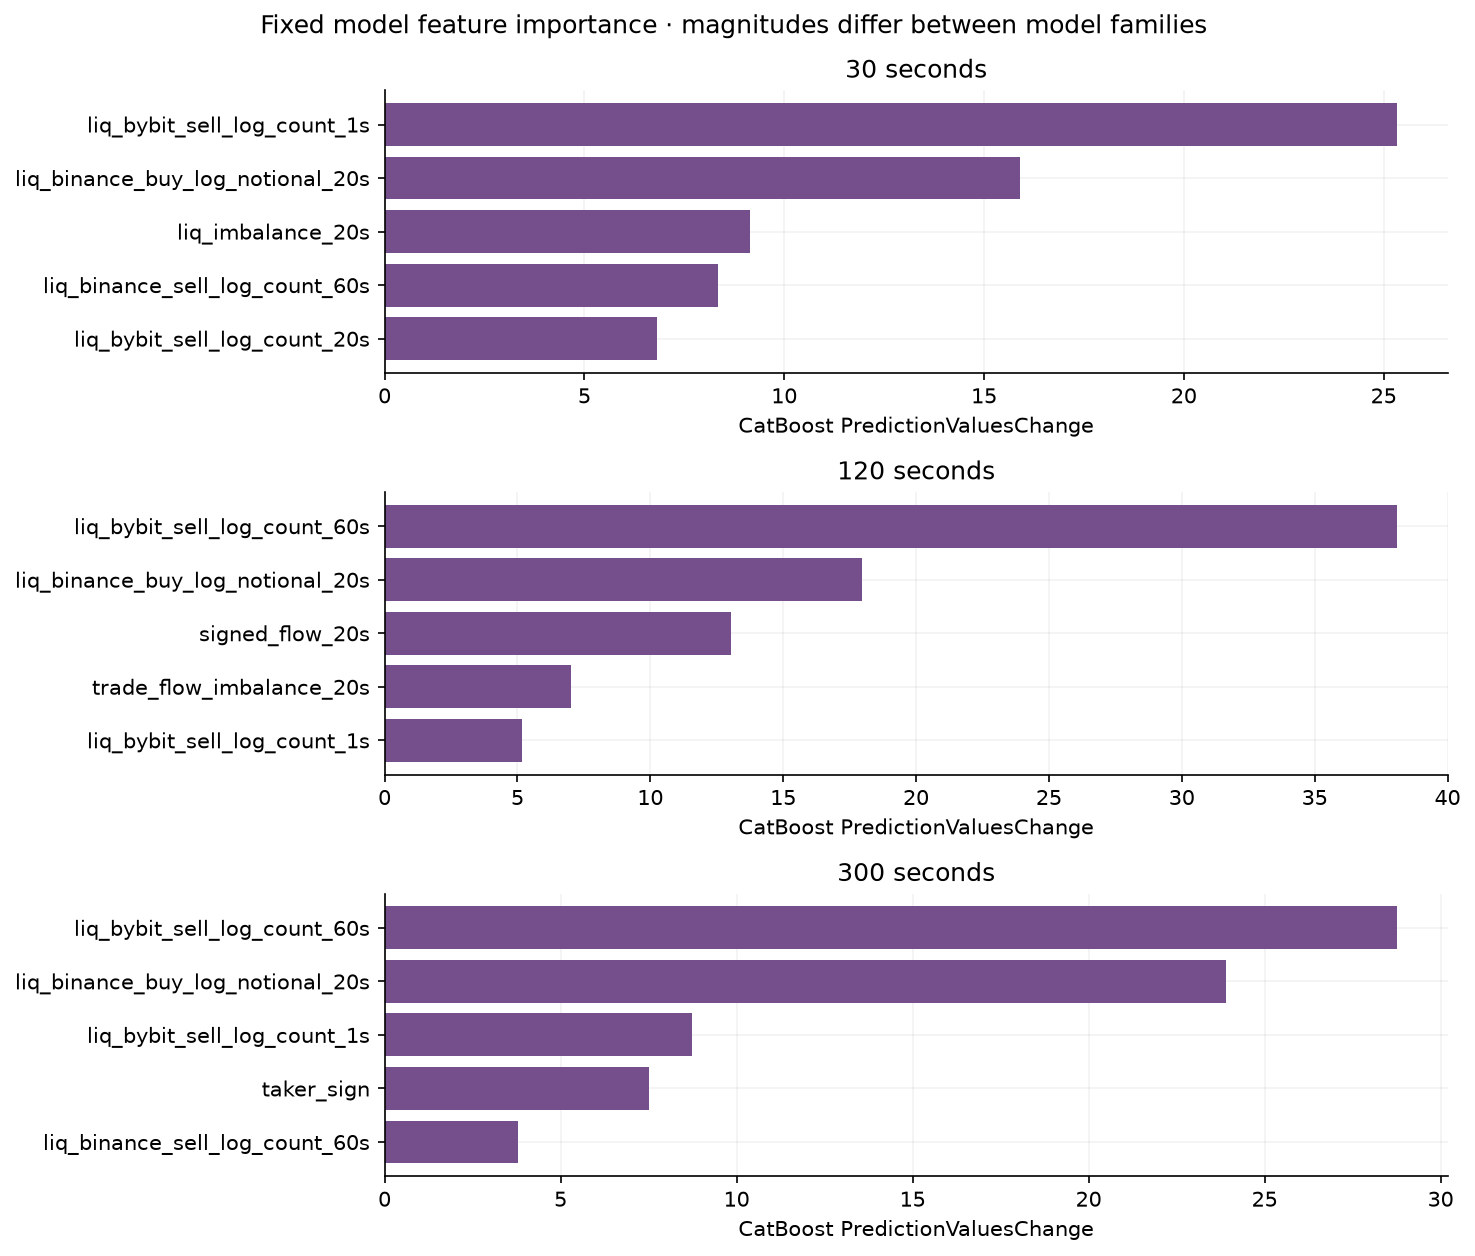

In [6]:
show(report.top_importance_figure('catboost'),'catboost_importance.png')

## Conclusion
The CatBoost extension is implemented, with frozen parameter/sample receipts and exact weighted-error accounting.
It improves the 120-second point Score but loses on 30 and 300 seconds. No adjusted paired comparison establishes
an incremental gain. Native fitted weights remain local because the supplied data's redistribution licence is unresolved.